## Part 1

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Get the data. Create a Ticker column identifying each of the companies.

In [4]:
AIG = pd.read_csv("data/AIG.csv")
AIG["Ticker"] = "AIG"

KEY = pd.read_csv("data/KEY.csv")
KEY["Ticker"] = "KEY"

NOW = pd.read_csv("data/NOW.csv")
NOW["Ticker"] = "NOW"

SNPS = pd.read_csv("data/SNPS.csv")
SNPS["Ticker"] = "SNPS"

Merging the data.

In [8]:
df = pd.concat([AIG, KEY, NOW, SNPS])
df.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker
0,2022-01-03,51.298,52.105,51.253,51.486,3376300,0.0,0.0,AIG
1,2022-01-04,52.257,53.361,52.060,52.930,5281300,0.0,0.0,AIG
2,2022-01-05,53.047,53.558,52.168,52.204,4639400,0.0,0.0,AIG
3,2022-01-06,53.146,53.397,51.845,53.101,6331600,0.0,0.0,AIG
4,2022-01-07,53.469,54.698,53.208,54.491,5318900,0.0,0.0,AIG


Ensure that Dates are correctly represented as datetime objects.

In [9]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date").sort_index()
df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker
Date,,,,,,,,
2022-01-03,51.298,52.105,51.253,51.486,3376300,0.0,0.0,AIG
2022-01-03,18.539,18.824,18.516,18.642,6834300,0.0,0.0,KEY
2022-01-03,367.130,371.730,358.640,361.100,674800,0.0,0.0,SNPS
2022-01-03,129.632,130.282,125.084,126.028,5218500,0.0,0.0,NOW
2022-01-04,360.100,361.460,345.410,352.990,895200,0.0,0.0,SNPS


#### Is there a company that has no difference between the High and Low columns for any trading day? What does it mean for the stock’s trading behavior on such days?

In [17]:
print(sum(df[df["Ticker"] == "AIG"]["High"] == df[df["Ticker"] == "AIG"]["Low"]))
print(sum(df[df["Ticker"] == "KEY"]["High"] == df[df["Ticker"] == "KEY"]["Low"]))
print(sum(df[df["Ticker"] == "SNPS"]["High"] == df[df["Ticker"] == "SNPS"]["Low"]))
print(sum(df[df["Ticker"] == "NOW"]["High"] == df[df["Ticker"] == "NOW"]["Low"]))

0
0
0
0


No, there is no trading day, where there is no difference between the High and Low columns for any company.

#### What is the highest and lowest price price each company recorded?

In [18]:
g = df.groupby("Ticker")
pd.DataFrame({
    "highest": g["High"].max(),
    "lowest": g["Low"].min(),
})

,highest,lowest
Ticker,,
AIG,85.638,42.181
KEY,21.480,7.100
NOW,239.618,67.400
SNPS,651.730,255.020


#### Calculate logarithmic returns from Close. For each company, report min, max, mean, standard deviation, and skewness of returns.

In [26]:
df["ret"] = df["Close"] - df["Close"].shift(1)
df["log_ret"] = np.log(df["ret"])

TypeError: log() got an unexpected keyword argument 'errors'

#### What is the median calendar weekly volume (i.e. sum of volume for a particular week) for each company?

In [31]:
weekly = df.groupby("Ticker")["Volume"].resample("W").sum()
weekly.groupby("Ticker").median()

Ticker
AIG     20160000.0
KEY     64778800.0
NOW     33366500.0
SNPS     4725600.0
Name: Volume, dtype: float64

#### Create a new column volume_class with categories (e.g., “Low”, “Medium”, “High”) based on volume tertiles within the given company.

## Part 2

In [48]:
comp = pd.read_csv("data/companies_no_subindustry.csv")
comp.head()

,Symbol,Security,GICS_Sector,hq,included,Founded
0,MMM,3M,Industrials,"Saint Paul, Minnesota",09.08.1976,1902
1,AOS,A. O. Smith,Industrials,"Milwaukee, Wisconsin",26.07.2017,1916
2,ABT,Abbott,Health Care,"North Chicago, Illinois",31.03.1964,1888
3,ABBV,AbbVie,Health Care,"North Chicago, Illinois",31.12.2012,2013 (1888)
4,ABMD,Abiomed,Health Care,"Danvers, Massachusetts",31.05.2018,1981


#### How many companies have missing inclusion dates (included column)?

In [49]:
comp.isna().sum()

Symbol          0
Security        0
GICS_Sector     0
hq              0
included       45
Founded         0
dtype: int64

45 companies have missing inclusion dates.

#### Remove companies with missing inclusion dates. Find the oldest and youngest constituent (in terms of inclusion date), and compute the median age of a constituent in years (median difference in years between today’s date and date Founded).

In [50]:
comp = comp.dropna(subset=["included"])
comp["included"] = pd.to_datetime(comp["included"], dayfirst=True, errors='coerce')
comp = comp.set_index("included").sort_index()
comp.head(20)

,Symbol,Security,GICS_Sector,hq,Founded
included,,,,,
1957-03-04,BA,Boeing,Industrials,"Chicago, Illinois",1916
1957-03-04,DTE,DTE Energy,Utilities,"Detroit, Michigan",1995
1957-03-04,EIX,Edison International,Utilities,"Rosemead, California",1886
1957-03-04,KR,Kroger,Consumer Staples,"Cincinnati, Ohio",1883
1957-03-04,KMB,Kimberly-Clark,Consumer Staples,"Irving, Texas",1872
1957-03-04,ETR,Entergy,Utilities,"New Orleans, Louisiana",1913
1957-03-04,MO,Altria,Consumer Staples,"Richmond, Virginia",1985
1957-03-04,EXC,Exelon,Utilities,"Chicago, Illinois",2000
1957-03-04,XOM,ExxonMobil,Energy,"Irving, Texas",1999


There are many oldest constitutents in terms of inclusion dates, because many were included on the same day.

#### Compute the number of companies in each of the sectors and visualize proportions (e.g., pie chart).

In [52]:
comp["GICS_Sector"].value_counts()

GICS_Sector
Information Technology    68
Industrials               66
Health Care               60
Financials                55
Consumer Discretionary    52
Consumer Staples          33
Real Estate               30
Materials                 26
Utilities                 23
Communication Services    23
Energy                    22
Name: count, dtype: int64

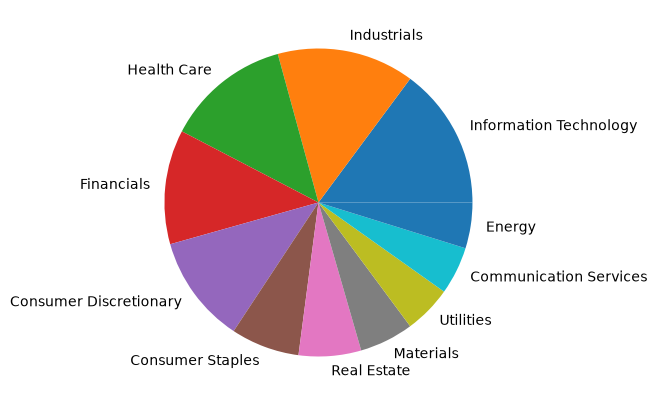

In [54]:
plot = comp["GICS_Sector"].value_counts().plot.pie(figsize=(5, 5))

#### Join this dataset with companies_subindustry.csv that you will also fond in the companies folder on the Google Drive. Merge based on an appropriate key and report subindustry distribution within the “Health Care” GICS sector (e.g., bar plot).

In [58]:
sub = pd.read_csv("data/companies_subindustry.csv")
sub.head()

,Symbol,subindustry
0,MMM,Industrial Conglomerates
1,AOS,Building Products
2,ABT,Health Care Equipment
3,ABBV,Pharmaceuticals
4,ABMD,Health Care Equipment


In [60]:
merged = comp.merge(sub, on="Symbol")
merged[merged["GICS_Sector"] == "Health Care"]["subindustry"].value_counts()

subindustry
Health Care Equipment             18
Pharmaceuticals                    9
Biotechnology                      7
Life Sciences Tools & Services     7
Managed Health Care                5
Health Care Distributors           4
Health Care Supplies               4
Health Care Services               3
Health Care Facilities             3
Name: count, dtype: int64

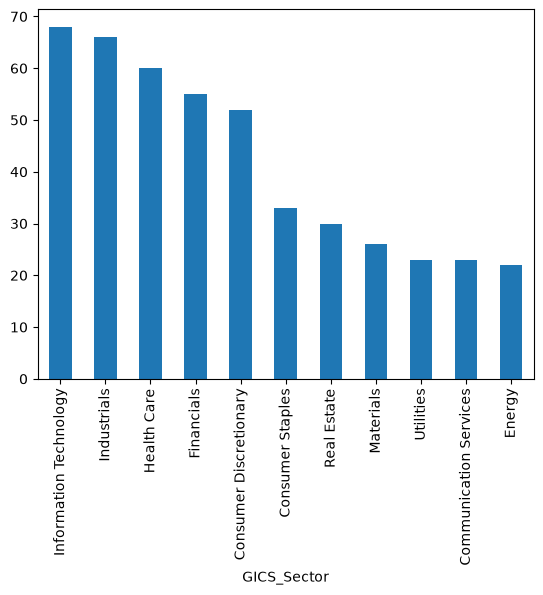

In [61]:
plot = comp["GICS_Sector"].value_counts().plot.bar()

## Part 3

#### Generate four random variables from four different distributions (e.g., Normal, Uniform, etc.), each with a random number of observations between 100 and 500.

In [66]:
rng = np.random.default_rng(42)
normal_sample = rng.normal(loc=0, scale=1, size=rng.integers(100, 500, 1))
uniform_sample = rng.uniform(low=0, high=1, size=rng.integers(100, 500, 1))
print(normal_sample)